# A/B-тест активации

Синтетический эксперимент: новый экран после проверки личности. Основной результат — активация за семь суток. План проверки находится в experiment.md.

In [1]:
import pandas as pd
from IPython.display import Image, display
from scipy.stats import chisquare
from analysis import load_metrics, compare_binary, planned_sample, run

metrics, quality = load_metrics()
print(quality)

{'users': 24000, 'raw_events': 66150, 'duplicate_events': 655}


## Полнота и распределение

In [2]:
counts = metrics["variant"].value_counts().reindex(["A", "B"])
print(counts.to_string())
print("SRM p-value:", chisquare(counts, f_exp=[len(metrics) / 2] * 2).pvalue)
print("План на группу:", planned_sample())
print(pd.crosstab(metrics["platform"], metrics["variant"], normalize="columns").round(4).to_string())

variant
A    11976
B    12024
SRM p-value: 0.7566836450106742
План на группу: 7157
variant       A       B
platform               
android   0.591  0.5801
ios       0.409  0.4199


У всех назначенных пользователей завершено окно наблюдения. 655 повторов событий удалены. Пользователи без целевого события остаются в знаменателе. SRM не обнаружен; платформы проверяются как описательный баланс.

In [3]:
funnel = metrics.groupby("variant").agg(users=("user_id", "count"), identity_started=("identity_started", "sum"), identity_passed=("identity_passed", "sum"), activated_7d=("activated_7d", "sum"))
print(funnel.to_string())

         users  identity_started  identity_passed  activated_7d
variant                                                        
A        11976              9757             7570          2670
B        12024              9916             7751          2990


## Основная метрика

In [4]:
primary = compare_binary(metrics, "activated_7d")
print("A:", round(primary["a_rate"] * 100, 2), "%")
print("B:", round(primary["b_rate"] * 100, 2), "%")
print("Разница, п.п.:", round(primary["difference"] * 100, 2))
print("95% ДИ, п.п.:", round(primary["ci_low"] * 100, 2), round(primary["ci_high"] * 100, 2))
print("p-value:", primary["p_value"])

A: 22.29 %
B: 24.87 %
Разница, п.п.: 2.57
95% ДИ, п.п.: 1.5 3.65
p-value: 2.6842413924627374e-06


Разница +2,57 п.п., нижняя граница интервала выше нуля. Это свидетельство роста в рамках симуляции. Относительный рост 11,54% не следует путать с ростом на 11,54 процентного пункта.

Разница ошибок, п.п.: 0.16
Односторонняя верхняя граница, п.п.: 0.54
Лимит ухудшения, п.п.: 1.0
{
  "quality": {
    "users": 24000,
    "raw_events": 66150,
    "duplicate_events": 655
  },
  "planned_users_per_group": 7157,
  "srm_p_value": 0.7566836450106742,
  "primary": {
    "a_users": 11976,
    "b_users": 12024,
    "a_successes": 2670,
    "b_successes": 2990,
    "a_rate": 0.22294589178356713,
    "b_rate": 0.24866932801064537,
    "difference": 0.025723436227078234,
    "relative_uplift": 0.1153797274365127,
    "p_value": 2.6842413924627374e-06,
    "ci_low": 0.014987553163239374,
    "ci_high": 0.03645931929091709,
    "one_sided_upper": 0.034733273313562386
  },
  "guardrail": {
    "a_users": 11976,
    "b_users": 12024,
    "a_successes": 387,
    "b_successes": 408,
    "a_rate": 0.03231462925851703,
    "b_rate": 0.033932135728542916,
    "difference": 0.001617506470025884,
    "relative_uplift": 0.05005492890188627,
    "p_value": 0.48386727537477925,
    "ci_low": -

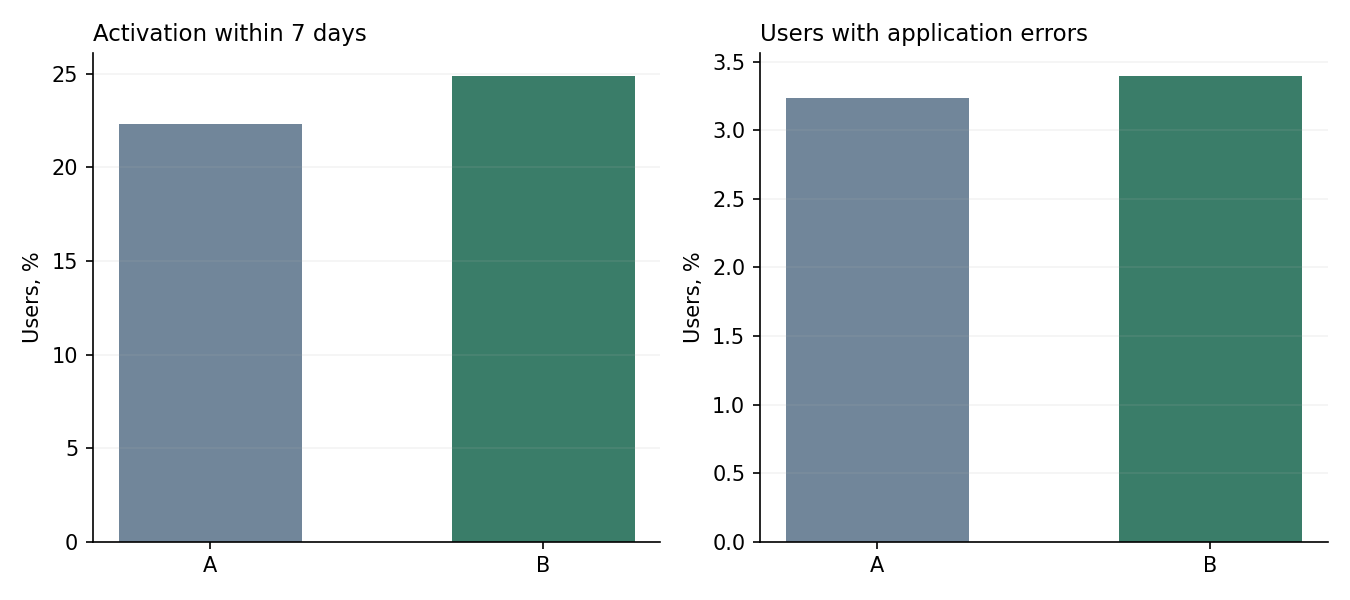

In [5]:
guardrail = compare_binary(metrics, "had_error_7d")
print("Разница ошибок, п.п.:", round(guardrail["difference"] * 100, 2))
print("Односторонняя верхняя граница, п.п.:", round(guardrail["one_sided_upper"] * 100, 2))
print("Лимит ухудшения, п.п.:", 1.0)
report = run()
display(Image(filename="reports/metrics.png"))

## Решение

В учебном сценарии B проходит правило: основной показатель вырос, а верхняя граница ухудшения по ошибкам ниже 1 п.п. Здесь важна именно граница, а не незначимый p-value ошибок.

Данные заданы генератором, поэтому это демонстрация расчётов, а не оценка реального эффекта. Дополнительные срезы не используются для поиска значимого результата.